# Feature Importance Analysis

Feature importance is analysed for the full pipeline in a way that supports the generalisation question:

1. **Selection stability** – which features are selected by the cross-vehicle stable selection in every LOVO fold.
2. **Permutation importance on the unseen vehicle-driver** – how much macro-F1 on the held-out vehicle drops when a feature is shuffled. Unlike built-in tree importance, this measures what actually matters for generalisation and is comparable across models.
3. **Grouped importance** – by sensor, channel type and feature domain.

In [ ]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
assert os.path.exists(os.path.join(CODE_DIR, 'c4_pipeline.py')), \
    'Upload c4_pipeline.py to MyDrive/PVS_Code/ before running this notebook.'
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.ensure_dirs()
c4.check_setup();

Mounted at /content/drive
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams['figure.dpi'] = 110
CL = c4.CLASSES
COLORS = {'good': 'tab:green', 'regular': 'goldenrod', 'bad': 'tab:red'}

In [ ]:
from sklearn.inspection import permutation_importance
data = c4.load_data()
CONFIGS = c4.ablation_configs()
FULL = 'C6 + Stable selection (FULL)'
final = pd.read_csv(os.path.join(c4.RESULTS_DIR, 'final_results.csv'))
MODEL = final[(final.config == FULL) & (final.split == 'LOVO')].groupby('model')['macro_f1'].mean().idxmax()
print('Model analysed:', MODEL)

Model analysed: XGB


In [ ]:
sel_count, perm = {}, []
for fname, trm, tem in data.splits()['LOVO']:
    cfg = CONFIGS[FULL]
    tr = c4.train_index(data, cfg, trm)
    te = np.where(tem & data.E)[0]
    X, info = c4.prepare(data, cfg, tr)
    for c in info['selected']:
        sel_count[c] = sel_count.get(c, 0) + 1
    m = c4.fit(MODEL, X.values[tr], data.y[tr])
    pi = permutation_importance(m, X.values[te], data.y[te], scoring='f1_macro', n_repeats=5,
                                random_state=42, n_jobs=-1)
    perm.append(pd.DataFrame({'feature': X.columns, 'fold': fname, 'importance': pi.importances_mean}))
    print('done', fname)
perm = pd.concat(perm, ignore_index=True)
n_folds = len(data.splits()['LOVO'])
stab = pd.Series(sel_count, name='folds selected').sort_values(ascending=False)
print(f'Features selected in all {n_folds} LOVO folds: {(stab == n_folds).sum()} of {len(stab)} distinct features')

done test=Fiat Bravo
done test=Fiat Palio
done test=VW Saveiro
Features selected in all 3 LOVO folds: 14 of 78 distinct features


,mean,std,folds selected
feature,,,
t__left_dashboard__acc_mag__mean,0.1419,0.0417,3
t__right_dashboard__gyro_fy__range,0.0134,0.0232,1
t__left_dashboard__gyro_mag__rms,0.0074,0.0083,2
t__right_dashboard__gyro_mag__rms,0.0061,0.0073,2
f__left_dashboard__gyro_mag__logpow,0.0051,0.0053,2
f__right_dashboard__acc_dy__centroid,0.0040,0.0069,1
f__left_dashboard__acc_dx__centroid,0.0038,0.0066,1
t__left_dashboard__gyro_mag__iqr,0.0037,0.0044,2
f__right_dashboard__gyro_fx__bprel_3-8,0.0033,0.0028,3


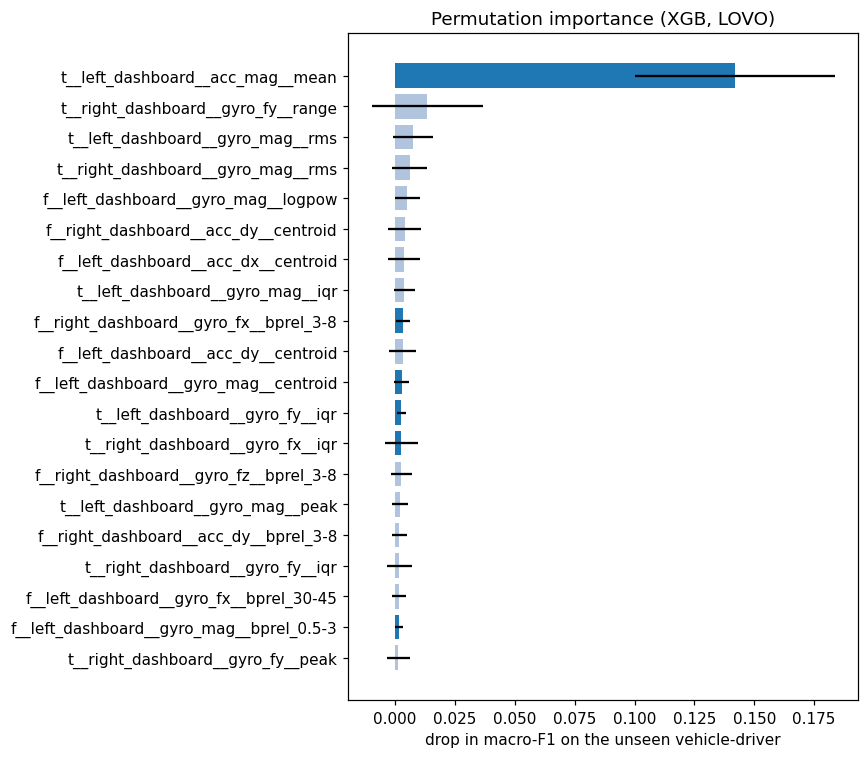

In [ ]:
# a feature that was not selected in a fold has importance 0 in that fold
imp_tab = perm.pivot_table(index='feature', columns='fold', values='importance').fillna(0)
imp = pd.DataFrame({'mean': imp_tab.mean(axis=1), 'std': imp_tab.std(axis=1)}).join(stab).sort_values('mean', ascending=False)
imp.to_csv(os.path.join(c4.RESULTS_DIR, 'permutation_importance_lovo.csv'))
display(imp.head(20).round(4))

top = imp.head(20).iloc[::-1]
plt.figure(figsize=(8, 7))
plt.barh(top.index, top['mean'], xerr=top['std'], color=['tab:blue' if s == n_folds else 'lightsteelblue'
                                                          for s in top['folds selected'].fillna(0)])
plt.xlabel('drop in macro-F1 on the unseen vehicle-driver'); plt.title(f'Permutation importance ({MODEL}, LOVO)')
plt.tight_layout(); plt.savefig(os.path.join(c4.RESULTS_DIR, 'permutation_importance.png'), dpi=150); plt.show()

## Grouped importance

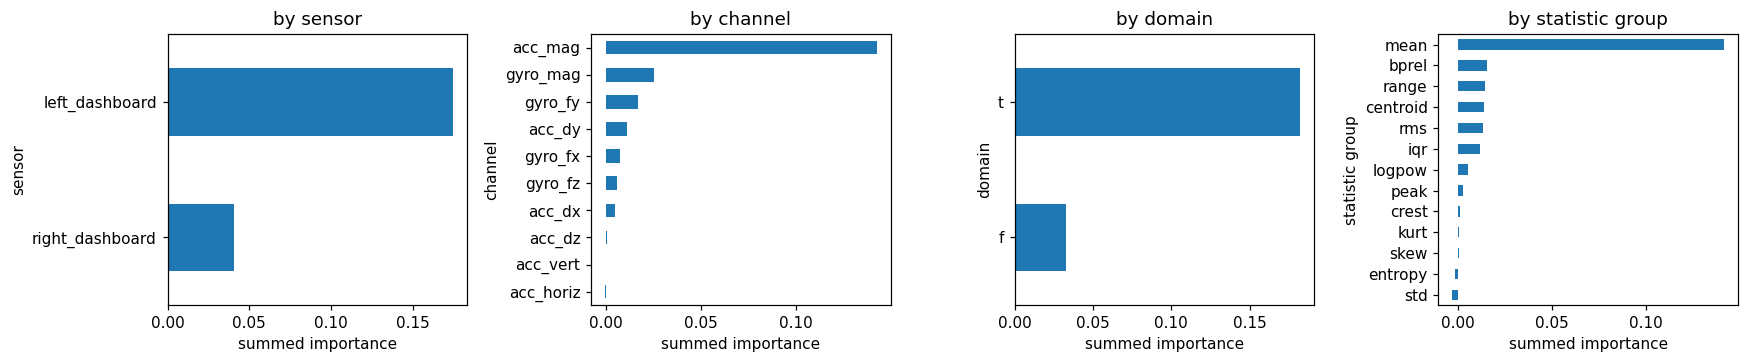

In [ ]:
parts = pd.DataFrame([c4.parse(f) for f in imp.index], index=imp.index, columns=['domain', 'sensor', 'channel', 'statistic'])
g = imp[['mean']].join(parts)
g['channel type'] = np.where(g.channel.isin(c4.ROBUST_CH), 'orientation-invariant', 'axis')
g['statistic group'] = g.statistic.str.replace(r'_.*', '', regex=True)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, ['sensor', 'channel', 'domain', 'statistic group']):
    g.groupby(col)['mean'].sum().sort_values().plot(kind='barh', ax=ax)
    ax.set_title(f'by {col}'); ax.set_xlabel('summed importance')
plt.tight_layout(); plt.savefig(os.path.join(c4.RESULTS_DIR, 'grouped_importance.png'), dpi=150); plt.show()

## Findings template
* Name the most important features and check that they are physically plausible (e.g. vertical vibration energy in the wheel-hop band).
* State whether the important features are stable across LOVO folds (dark bars) – stable, physically meaningful features support the generalisation claim.
* Compare with the earlier analysis, where magnetometer and temperature features appeared among the top features; those are no longer available to the model.
* Importance is associative, not causal.